In [ ]:
!pip install yfinance

Loaded 262 months of real data (2005-01 to 2026-10)

Momentum strategy (net of costs)
--------------------------------
  CAGR                    7.48%
  Volatility             11.68%
  Sharpe                   0.47
  Max drawdown          -19.13%
  Calmar                   0.39
  Positive months        54.20%
  Avg monthly turnover   25.57%

Benchmark 60/40
---------------
  CAGR                    8.03%
  Volatility              9.06%
  Sharpe                   0.67
  Max drawdown          -29.46%
  Calmar                   0.27
  Positive months        66.79%

  Months fully in cash:    7.63%


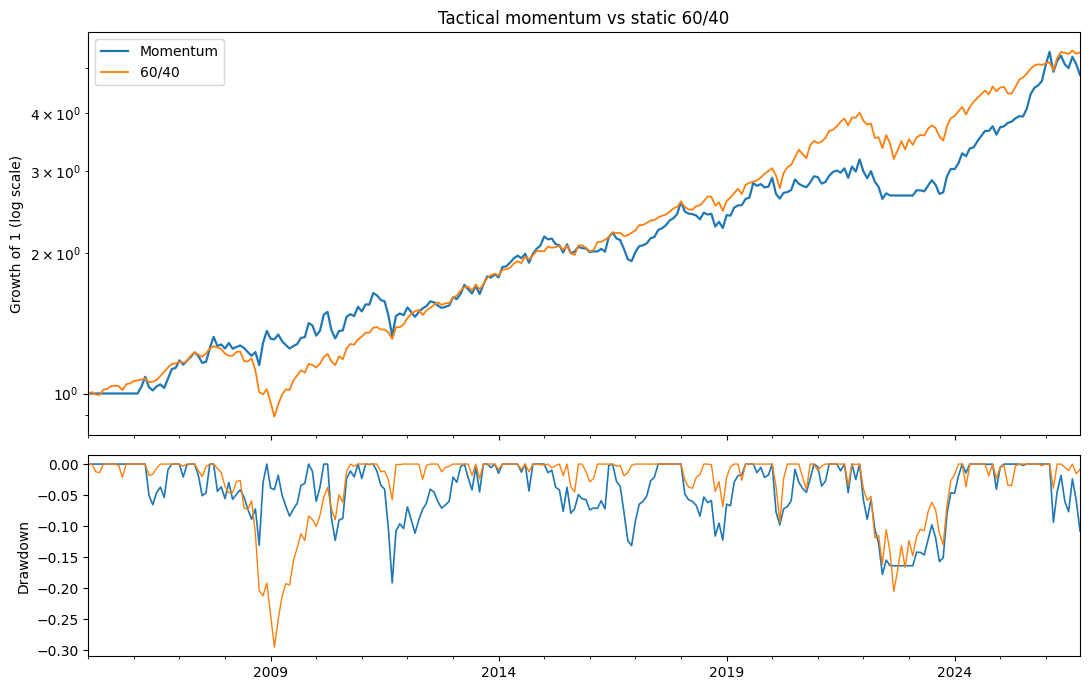

In [1]:
"""
Tactical asset allocation backtest: 12-month momentum, monthly rebalance.

Strategy
--------
Each month-end, rank a universe of ETFs by 12-month total return (skipping the
most recent month to avoid short-term reversal). Hold the top N equally
weighted for the following month. If an asset's momentum is negative, hold cash
instead (the "absolute momentum" filter).

Benchmark: static 60/40 equity/bond portfolio, monthly rebalanced.

Design choices
------------------------------------------
- Signals are computed on data up to month-end t and applied to returns in
  month t+1. No look-ahead.
- Transaction costs are charged on turnover, not per trade.
- Monthly data only. Daily rebalancing on monthly signals adds noise, not alpha.
- Results are gross of tax and assume fills at month-end close.

Limitations
---------------------------------------------------------
- ETF history is short and survivorship-biased toward funds that still exist.
- One parameter set. Robustness needs a sweep over lookback and top-N.
- No regime analysis. A strategy that works in aggregate may fail persistently
  in certain decades.
"""

import numpy as np
import pandas as pd

# ----------------------------------------------------------------------------
# Parameters
# ----------------------------------------------------------------------------

TICKERS = ["SPY", "EFA", "EEM", "IEF", "TLT", "GLD", "VNQ"]
BENCHMARK = {"SPY": 0.60, "IEF": 0.40}

START = "2005-01-01"
END = None                 # None = today

LOOKBACK_MONTHS = 12       # momentum formation window
SKIP_MONTHS = 1            # skip most recent month (reversal effect)
TOP_N = 3                  # number of assets held
ABSOLUTE_MOMENTUM = True   # move to cash when momentum is negative
COST_BPS = 10              # one-way transaction cost, basis points
RISK_FREE_ANNUAL = 0.02    # for Sharpe; set to 0 if you prefer


# ----------------------------------------------------------------------------
# Data
# ----------------------------------------------------------------------------

def load_prices(tickers, start, end):
    """Monthly adjusted close prices. Falls back to simulated data offline."""
    try:
        import yfinance as yf
        raw = yf.download(tickers, start=start, end=end, auto_adjust=True,
                          progress=False)["Close"]
        monthly = raw.resample("ME").last().dropna(how="all")
        if monthly.empty:
            raise ValueError("no rows returned")
        print(f"Loaded {len(monthly)} months of real data "
              f"({monthly.index[0]:%Y-%m} to {monthly.index[-1]:%Y-%m})")
        return monthly.dropna()
    except Exception as exc:
        print(f"Download failed ({exc}). Using simulated data instead.")
        return _simulate_prices(tickers, start, end)


def _simulate_prices(tickers, start, end, seed=7):
    """Geometric random walks, so the engine can be tested without a network."""
    rng = np.random.default_rng(seed)
    idx = pd.date_range(start, end or "2026-09-30", freq="ME")
    drift = rng.uniform(0.002, 0.007, len(tickers))
    vol = rng.uniform(0.02, 0.06, len(tickers))
    shocks = rng.normal(drift, vol, size=(len(idx), len(tickers)))
    prices = 100 * np.exp(np.cumsum(shocks, axis=0))
    return pd.DataFrame(prices, index=idx, columns=tickers)


# ----------------------------------------------------------------------------
# Strategy
# ----------------------------------------------------------------------------

def momentum_weights(prices):
    """Target weights per month-end, applied to the FOLLOWING month's returns."""
    total = LOOKBACK_MONTHS + SKIP_MONTHS
    signal = prices.shift(SKIP_MONTHS) / prices.shift(total) - 1

    weights = pd.DataFrame(0.0, index=prices.index, columns=prices.columns)

    for date, row in signal.iterrows():
        scores = row.dropna()
        if scores.empty:
            continue
        picks = scores.nlargest(TOP_N)
        if ABSOLUTE_MOMENTUM:
            picks = picks[picks > 0]          # anything else sits in cash
        if len(picks) == 0:
            continue
        weights.loc[date, picks.index] = 1.0 / TOP_N

    return weights


def run_backtest(prices, weights, cost_bps=COST_BPS):
    """Apply weights decided at t to returns realised over t+1."""
    returns = prices.pct_change()
    held = weights.shift(1).fillna(0.0)

    gross = (held * returns).sum(axis=1)
    turnover = held.diff().abs().sum(axis=1).fillna(0.0)
    costs = turnover * cost_bps / 10_000

    net = gross - costs
    return net, turnover


def benchmark_returns(prices, mix=BENCHMARK):
    returns = prices.pct_change()
    cols = [c for c in mix if c in returns.columns]
    w = pd.Series({c: mix[c] for c in cols})
    w = w / w.sum()
    return (returns[cols] * w).sum(axis=1)


# ----------------------------------------------------------------------------
# Performance statistics
# ----------------------------------------------------------------------------

def drawdown_series(returns):
    curve = (1 + returns).cumprod()
    return curve / curve.cummax() - 1


def summarise(returns, name, turnover=None):
    r = returns.dropna()
    years = len(r) / 12
    total_growth = (1 + r).prod()

    cagr = total_growth ** (1 / years) - 1
    vol = r.std() * np.sqrt(12)
    excess = cagr - RISK_FREE_ANNUAL
    sharpe = excess / vol if vol > 0 else np.nan
    max_dd = drawdown_series(r).min()
    calmar = cagr / abs(max_dd) if max_dd < 0 else np.nan
    hit = (r > 0).mean()

    stats = {
        "CAGR": f"{cagr:7.2%}",
        "Volatility": f"{vol:7.2%}",
        "Sharpe": f"{sharpe:7.2f}",
        "Max drawdown": f"{max_dd:7.2%}",
        "Calmar": f"{calmar:7.2f}",
        "Positive months": f"{hit:7.2%}",
    }
    if turnover is not None:
        stats["Avg monthly turnover"] = f"{turnover.mean():7.2%}"

    print(f"\n{name}")
    print("-" * len(name))
    for k, v in stats.items():
        print(f"  {k:<22}{v}")
    return stats


def plot_results(strategy, benchmark):
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("\nmatplotlib not available, skipping chart")
        return

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                                   gridspec_kw={"height_ratios": [2, 1]})

    (1 + strategy.fillna(0)).cumprod().plot(ax=ax1, label="Momentum", lw=1.6)
    (1 + benchmark.fillna(0)).cumprod().plot(ax=ax1, label="60/40", lw=1.3)
    ax1.set_yscale("log")
    ax1.set_ylabel("Growth of 1 (log scale)")
    ax1.legend()
    ax1.set_title("Tactical momentum vs static 60/40")

    drawdown_series(strategy.fillna(0)).plot(ax=ax2, lw=1.2)
    drawdown_series(benchmark.fillna(0)).plot(ax=ax2, lw=1.0)
    ax2.set_ylabel("Drawdown")
    ax2.set_xlabel("")

    plt.tight_layout()
    plt.show()


# ----------------------------------------------------------------------------

def main():
    prices = load_prices(TICKERS, START, END)

    weights = momentum_weights(prices)
    strategy, turnover = run_backtest(prices, weights)
    bench = benchmark_returns(prices)

    common = strategy.dropna().index.intersection(bench.dropna().index)
    strategy, bench, turnover = (strategy[common], bench[common],
                                 turnover[common])

    summarise(strategy, "Momentum strategy (net of costs)", turnover)
    summarise(bench, "Benchmark 60/40")

    cash_months = (weights.sum(axis=1) == 0).mean()
    print(f"\n  Months fully in cash:  {cash_months:7.2%}")

    plot_results(strategy, bench)


if __name__ == "__main__":
    main()